<a href="https://colab.research.google.com/github/1900690/cucumber-bbox-datasetmanager/blob/main/cucumber_result.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip /content/data.zip -d //content/data

In [2]:
import os
import glob
import pandas as pd

# 1. データの保存されているルートディレクトリを指定してください
# （Google Driveにアップロードしている場合は '/content/drive/MyDrive/調査結果' などに変更してください）
root_dir = '/content/data'

# 2. ルートディレクトリ以下のすべてのサブディレクトリから '*.csv' ファイルを再帰的に検索
search_pattern = os.path.join(root_dir, '**', '*.csv')
csv_files = glob.glob(search_pattern, recursive=True)

print(f"見つかったCSVファイルの総数: {len(csv_files)}件")

df_list = []

for file_path in csv_files:
    try:
        # 文字コードエラー（UnicodeDecodeError）が出る場合は 'cp932' または 'shift_jis' に変更してください
        # 例: pd.read_csv(file_path, encoding='cp932')
        df = pd.read_csv(file_path, encoding='utf-8')

        # オプション：どのディレクトリ（日付）のファイルか識別するための列を追加したい場合
        # 例: パスを分解して親ディレクトリ名（日付など）を取得
        path_parts = file_path.split(os.sep)
        if len(path_parts) > 1:
            df['source_folder'] = path_parts[-2] # フォルダ名を追加
            df['source_file'] = path_parts[-1]   # ファイル名を追加

        df_list.append(df)
    except Exception as e:
        print(f"読み込みエラー ({file_path}): {e}")

# 3. すべてのデータフレームを縦方向（行方向）に結合
if df_list:
    combined_df = pd.concat(df_list, ignore_index=True)

    print("\n--- 結合成功 ---")
    display(combined_df.head()) # Colab上で最初の数行を表示

    # 4. まとめたデータを新しいCSVファイルとして保存
    output_filename = 'combined_survey_result.csv'
    combined_df.to_csv(output_filename, index=False, encoding='utf-8-sig') # Excelで開く場合は 'utf-8-sig' がおすすめ
    print(f"統合ファイルを保存しました: {output_filename}")
else:
    print("結合対象のCSVファイルが見つかりませんでした。パスを確認してください。")

見つかったCSVファイルの総数: 497件

--- 結合成功 ---


,調査日,発芽日,収穫日,試験区,調査回数,番号,長さ(cm),太さ(cm),曲がり(cm),推定重量(g),ランク,source_folder,source_file
0,2026-10-16,NaN,2026-10-14,11,1,1,21.6,2.8,0.4,116.1,AM,20261014,2026-10-16_2026-10-14_区11_1回目.csv
1,2026-10-16,NaN,2026-10-14,11,1,2,20.8,2.6,2.5,99.8,BM,20261014,2026-10-16_2026-10-14_区11_1回目.csv
2,2026-10-16,NaN,2026-10-14,11,1,3,21.5,2.2,2.7,78.2,BM,20261014,2026-10-16_2026-10-14_区11_1回目.csv
3,2026-10-16,NaN,2026-10-14,11,1,4,21.3,2.7,2.4,106.3,BM,20261014,2026-10-16_2026-10-14_区11_1回目.csv
4,2026-10-16,NaN,2026-10-14,5,2,1,22.5,2.5,3.2,95.7,CM,20261014,2026-10-16_2026-10-14_区5_2回目.csv


統合ファイルを保存しました: combined_survey_result.csv


In [3]:
import pandas as pd

# 1. 結合済みのCSVファイルを読み込む
input_file = '/content/combined_survey_result.csv'
# 文字化け対策として utf-8-sig を指定しています
df = pd.read_csv(input_file, encoding='utf-8-sig')

# 2. 「収穫日」列を日付型に変換する（文字列のままだと正しい順序で並び替わらないため）
# ※もし列名が「収穫日」ではなく別の名前（例: 'harvest_date' など）の場合は、適宜書き換えてください
df['収穫日'] = pd.to_datetime(df['収穫日'], errors='coerce')

# 3. 収穫日を基準に並び替え
# 昇順（古い順・過去から未来）にする場合は ascending=True
# 降順（新しい順・未来から過去）にする場合は ascending=False に変更してください
df_sorted = df.sort_values(by='収穫日', ascending=True)

# （オプション）日付の表示形式を整えたい場合（例: YYYY-MM-DD）はコメントアウトを外してください
# df_sorted['収穫日'] = df_sorted['収穫日'].dt.strftime('%Y-%m-%d')

# 4. Colab上で最初の数行を表示して確認
print("\n--- 並び替え後のデータ（先頭5行） ---")
display(df_sorted.head())

# 5. 並び替えた結果を新しいCSVファイルとして保存
output_file = '/content/sorted_survey_result.csv'
df_sorted.to_csv(output_file, index=False, encoding='utf-8-sig')
print(f"\n並び替えたファイルを保存しました: {output_file}")


--- 並び替え後のデータ（先頭5行） ---


,調査日,発芽日,収穫日,試験区,調査回数,番号,長さ(cm),太さ(cm),曲がり(cm),推定重量(g),ランク,source_folder,source_file
886,2026-09-15,NaN,2026-09-15,8,1,1,20.5,2.8,0.5,111.0,AM,20260915,2026-09-15_2026-09-15_区8_1回目.csv
876,2026-09-15,NaN,2026-09-15,1,1,1,20.3,3.0,4.1,127.6,規格外,20260915,2026-09-15_2026-09-15_区1_1回目.csv
877,2026-09-15,NaN,2026-09-15,6,1,1,18.7,2.2,0.2,64.3,AM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
878,2026-09-15,NaN,2026-09-15,6,1,2,18.7,2.4,2.9,75.6,BM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
879,2026-09-15,NaN,2026-09-15,3,1,1,21.6,3.1,0.3,141.9,規格外,20260915,2026-09-15_2026-09-15_区3_1回目.csv



並び替えたファイルを保存しました: /content/sorted_survey_result.csv


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
【1. 試験区ごとの基本統計量（平均値）】


,長さ(cm),太さ(cm),曲がり(cm),推定重量(g)
試験区,,,,
1,19.896063,2.400787,1.956693,83.781102
2,20.216556,2.335762,1.971523,81.202649
3,20.023952,2.373653,1.907186,82.537725
4,19.646809,2.397872,1.674468,82.402128
5,19.930496,2.376596,1.524823,83.110638
6,20.229703,2.339604,1.935644,82.319802
7,20.096479,2.455634,1.776056,88.109859
8,20.348936,2.507801,1.583688,93.309220
9,20.137681,2.516667,1.755797,92.447101



【2. 一元配置分散分析 (ANOVA) の結果】


,測定項目,F値,p値,判定
0,長さ(cm),1.779987,0.052442,有意差なし
1,太さ(cm),3.901552,0.000013,有意差あり (*)
2,曲がり(cm),1.641577,0.081427,有意差なし
3,推定重量(g),3.583281,0.000052,有意差あり (*)



【3. テューキーの多重比較 (Tukey HSD) - 推定重量(g)】
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2  -2.5785    1.0 -15.3974 10.2405  False
     1      3  -1.2434    1.0 -13.7787 11.2919  False
     1      4   -1.379    1.0  -14.404  11.646  False
     1      5  -0.6705    1.0 -13.6955 12.3545  False
     1      6  -1.4613    1.0  -15.656 12.7334  False
     1      7   4.3288 0.9951  -8.6745  17.332  False
     1      8   9.5281 0.4105  -3.4969 22.5531  False
     1      9    8.666 0.5745  -4.4259 21.7579  False
     1     10   8.8918 0.5275  -4.1553 21.9388  False
     1     11   6.4661 0.9171  -6.9481 19.8803  False
     1     12  12.8016 0.1324  -1.5137 27.1168  False
     2      3   1.3351    1.0  -10.621 13.2912  False
     2      4   1.1995    1.0 -11.2691  13.668  False
     2      5    1.908    1.0 -10.5605 14.3765  False
     2      6   1.1172    1.0 -12.5687  14.

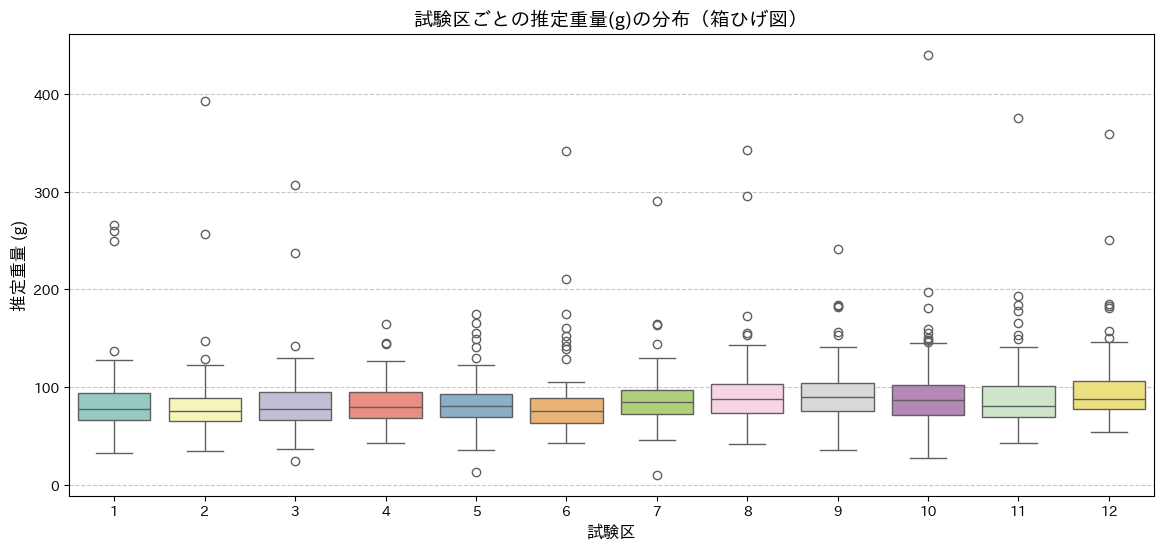

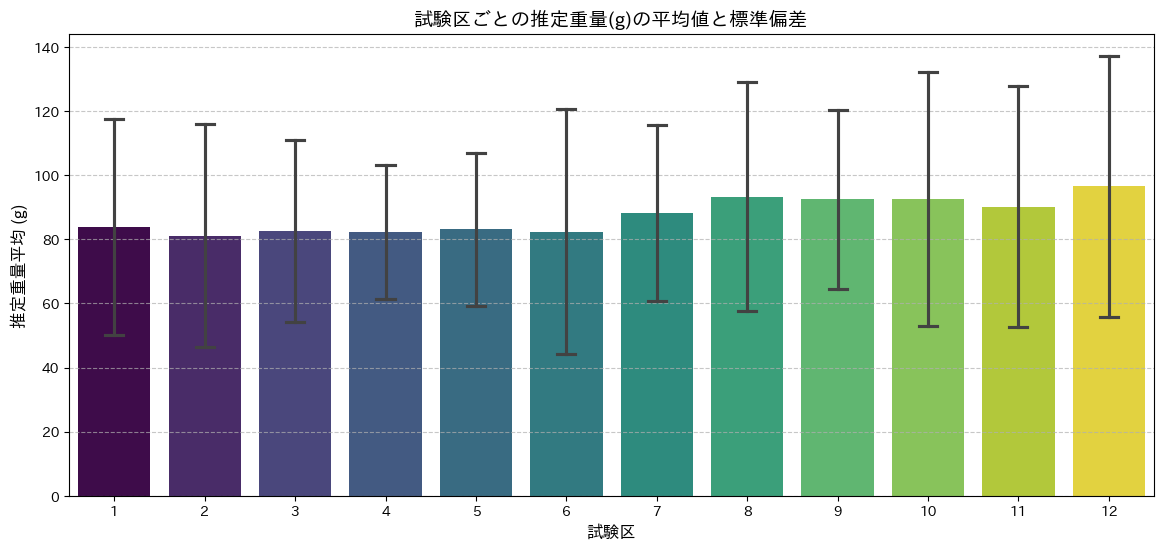

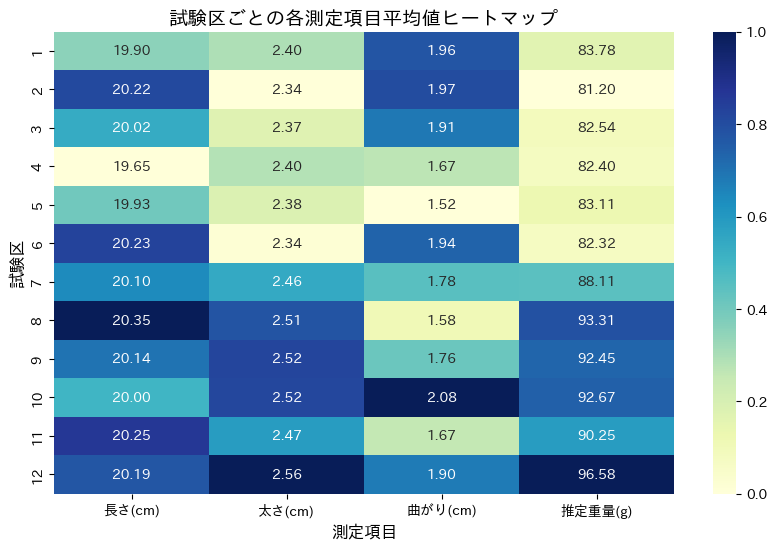


`japanize-matplotlib` を適用したグラフが正常に生成されました。


In [1]:
# 1. japanize-matplotlib のインストール
!pip install japanize-matplotlib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib # これをインポートするだけで日本語が正常表示されます
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 2. データの読み込み
file_path = 'sorted_survey_result.csv'
df = pd.read_csv(file_path, encoding='utf-8-sig')

# 分析対象の数値列
target_cols = ['長さ(cm)', '太さ(cm)', '曲がり(cm)', '推定重量(g)']

print("=" * 60)
print("【1. 試験区ごとの基本統計量（平均値）】")
print("=" * 60)
mean_df = df.groupby('試験区')[target_cols].mean()
display(mean_df)

print("\n" + "=" * 60)
print("【2. 一元配置分散分析 (ANOVA) の結果】")
print("=" * 60)
anova_results = []
for col in target_cols:
    groups = [group[col].dropna() for name, group in df.groupby('試験区')]
    f_val, p_val = stats.f_oneway(*groups)
    sig = "有意差あり (*)" if p_val < 0.05 else "有意差なし"
    anova_results.append({'測定項目': col, 'F値': f_val, 'p値': p_val, '判定': sig})

anova_df = pd.DataFrame(anova_results)
display(anova_df)

print("\n" + "=" * 60)
print("【3. テューキーの多重比較 (Tukey HSD) - 推定重量(g)】")
print("=" * 60)
tukey = pairwise_tukeyhsd(endog=df['推定重量(g)'].dropna(), groups=df.dropna(subset=['推定重量(g)'])['試験区'], alpha=0.05)
print(tukey)

print("\n" + "=" * 60)
print("【4. グラフの生成と保存】")
print("=" * 60)

# グラフ1: 箱ひげ図（Boxplot）
plt.figure(figsize=(14, 6))
sns.boxplot(x='試験区', y='推定重量(g)', data=df, palette='Set3', hue='試験区', legend=False)
plt.title('試験区ごとの推定重量(g)の分布（箱ひげ図）', fontsize=14, fontweight='bold')
plt.xlabel('試験区', fontsize=12)
plt.ylabel('推定重量 (g)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('/content/boxplot_estimated_weight.png', dpi=300, bbox_inches='tight')
plt.show()

# グラフ2: 平均値とエラーバーのグラフ
plt.figure(figsize=(14, 6))
sns.barplot(x='試験区', y='推定重量(g)', data=df, errorbar='sd', palette='viridis', capsize=0.2, hue='試験区', legend=False)
plt.title('試験区ごとの推定重量(g)の平均値と標準偏差', fontsize=14, fontweight='bold')
plt.xlabel('試験区', fontsize=12)
plt.ylabel('推定重量平均 (g)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('/content/barplot_estimated_weight.png', dpi=300, bbox_inches='tight')
plt.show()

# グラフ3: 各測定項目のヒートマップ
plt.figure(figsize=(10, 6))
norm_mean_df = (mean_df - mean_df.min()) / (mean_df.max() - mean_df.min())
sns.heatmap(norm_mean_df, annot=mean_df, fmt=".2f", cmap='YlGnBu', cbar=True)
plt.title('試験区ごとの各測定項目平均値ヒートマップ', fontsize=14, fontweight='bold')
plt.xlabel('測定項目', fontsize=12)
plt.ylabel('試験区', fontsize=12)
plt.savefig('/content/heatmap_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n`japanize-matplotlib` を適用したグラフが正常に生成されました。")

【1. 処理区ごとの基本統計量（平均値・標準偏差・データ数）】


長さ(cm)                    太さ(cm)                   曲がり(cm)            \
           mean       std count      mean       std count      mean       std   
処理区                                                                             
対照区   20.090171  1.754941   468  2.436752  0.485921   468  1.885897  1.611354   
弱摘葉区  20.015330  1.670152   561  2.449376  0.366456   561  1.634046  1.450024   
強摘葉区  20.117496  1.673115   583  2.417667  0.458797   583  1.914237  1.687610   

              推定重量(g)                   
     count       mean        std count  
処理区                                     
対照区    468  87.459829  34.912902   468  
弱摘葉区   561  87.792513  28.097865   561  
強摘葉区   583  86.278731  35.241392   583


【2. 一元配置分散分析 (ANOVA) - 処理区間での比較】


,測定項目,F値,p値,判定
0,長さ(cm),0.548507,0.577920,有意差なし
1,太さ(cm),0.761728,0.467027,有意差なし
2,曲がり(cm),5.246362,0.005357,有意差あり (*)
3,推定重量(g),0.333588,0.716398,有意差なし



【3. テューキーの多重比較 (Tukey HSD) - 曲がり(cm)】
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   対照区   弱摘葉区  -0.2519 0.0303 -0.4848 -0.0189   True
   対照区   強摘葉区   0.0283 0.9553 -0.2026  0.2593  False
  弱摘葉区   強摘葉区   0.2802  0.008  0.0601  0.5002   True
----------------------------------------------------

【4. グラフの個別表示・保存】


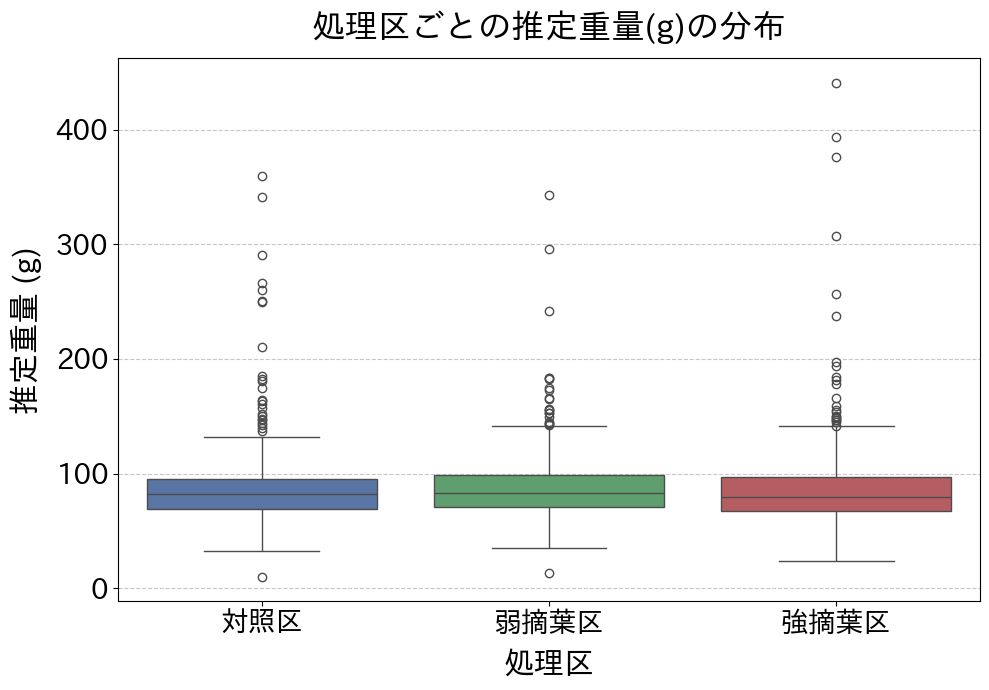

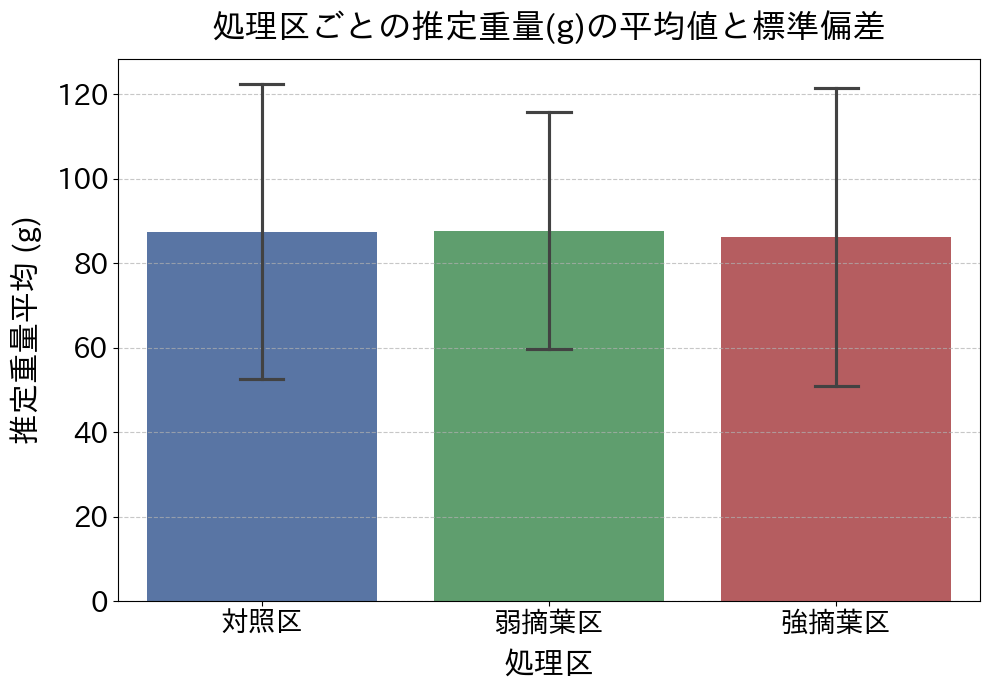

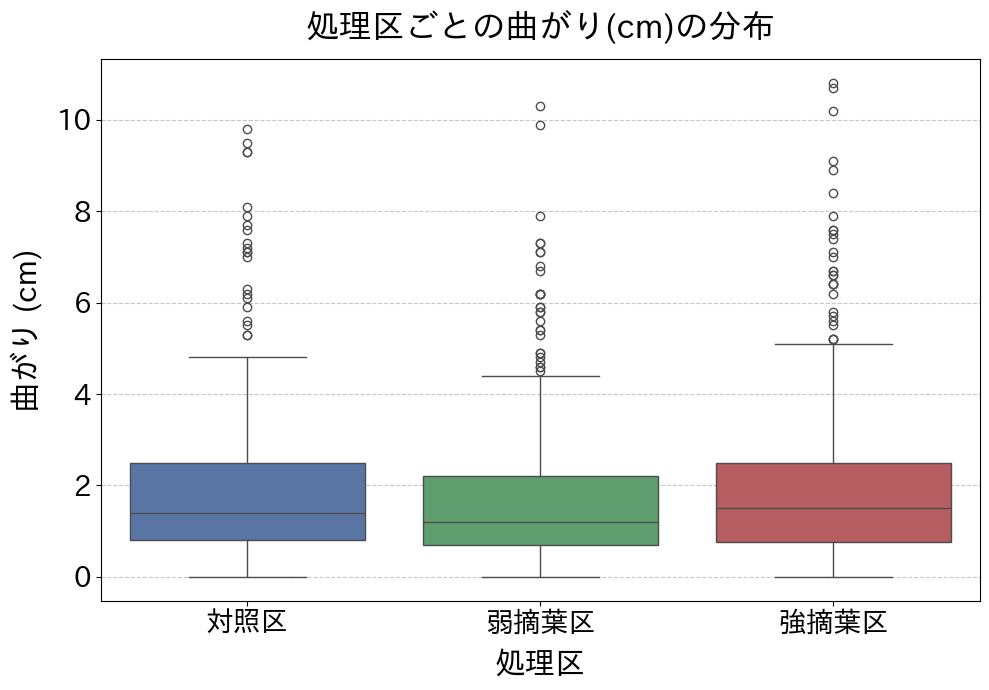

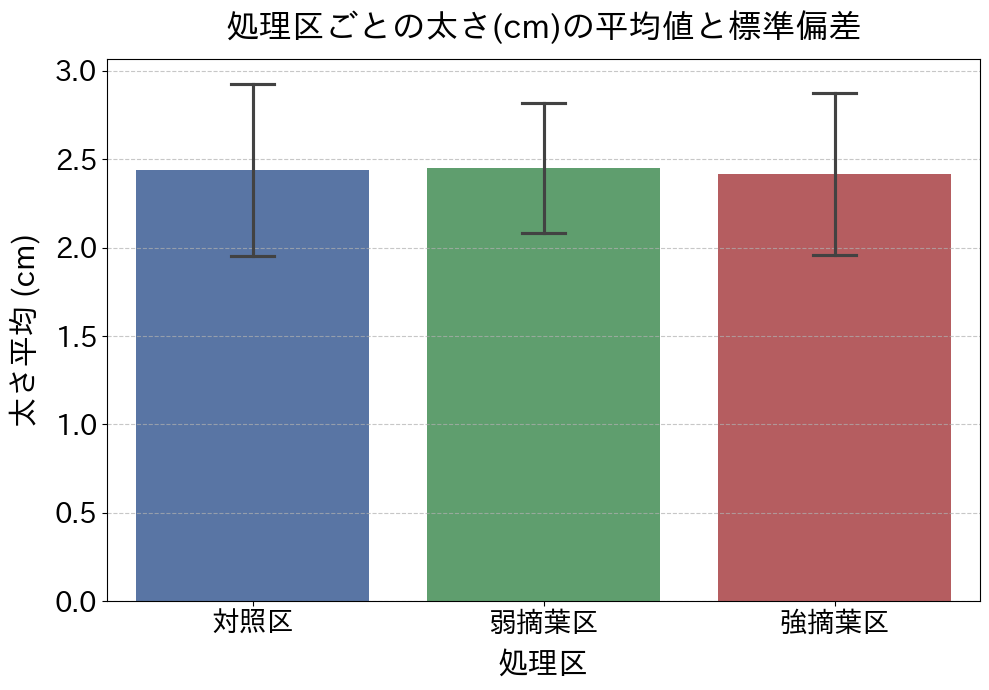

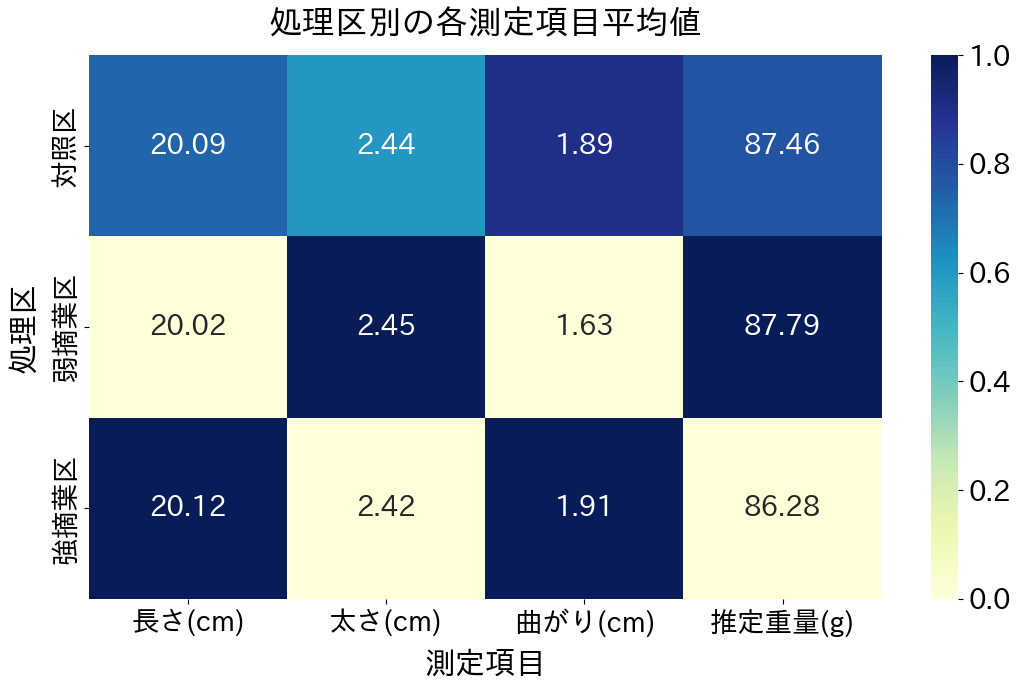


すべての個別グラフ（文字サイズ20pt以上）が正常に生成・保存されました。


In [2]:
!pip install japanize-matplotlib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib  # 日本語文字化け対策
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. データの読み込み
file_path = 'sorted_survey_result.csv'
df = pd.read_csv(file_path, encoding='utf-8-sig')

# 2. 試験区を処理区にマッピング
treatment_map = {
    2: '強摘葉区', 3: '強摘葉区', 10: '強摘葉区', 11: '強摘葉区',
    4: '弱摘葉区', 5: '弱摘葉区', 8: '弱摘葉区', 9: '弱摘葉区',
    1: '対照区', 6: '対照区', 7: '対照区', 12: '対照区'
}

df['処理区'] = df['試験区'].map(treatment_map)

# 表示順序を指定（比較しやすい順序）
treatment_order = ['対照区', '弱摘葉区', '強摘葉区']
target_cols = ['長さ(cm)', '太さ(cm)', '曲がり(cm)', '推定重量(g)']

print("=" * 70)
print("【1. 処理区ごとの基本統計量（平均値・標準偏差・データ数）】")
print("=" * 70)
summary_df = df.groupby('処理区')[target_cols].agg(['mean', 'std', 'count']).reindex(treatment_order)
display(summary_df)

print("\n" + "=" * 70)
print("【2. 一元配置分散分析 (ANOVA) - 処理区間での比較】")
print("=" * 70)
anova_results = []
for col in target_cols:
    groups = [group[col].dropna() for name, group in df.groupby('処理区')]
    f_val, p_val = stats.f_oneway(*groups)
    sig = "有意差あり (*)" if p_val < 0.05 else "有意差なし"
    anova_results.append({'測定項目': col, 'F値': f_val, 'p値': p_val, '判定': sig})

anova_df = pd.DataFrame(anova_results)
display(anova_df)

# 有意差が認められた項目（曲がり）について多重比較を実行
print("\n" + "=" * 70)
print("【3. テューキーの多重比較 (Tukey HSD) - 曲がり(cm)】")
print("=" * 70)
tukey = pairwise_tukeyhsd(endog=df['曲がり(cm)'].dropna(), groups=df.dropna(subset=['曲がり(cm)'])['処理区'], alpha=0.05)
print(tukey)

# ==============================================================
# 4. グラフの個別生成 (fontsize=20以上)
# ==============================================================
print("\n" + "=" * 70)
print("【4. グラフの個別表示・保存】")
print("=" * 70)

# フォントサイズを一括設定
FONT_TITLE = 24
FONT_LABEL = 22
FONT_TICK = 20

# カラーパレットの設定
custom_palette = {'対照区': '#4C72B0', '弱摘葉区': '#55A868', '強摘葉区': '#C44E52'}

# --- グラフ1: 推定重量(g) の箱ひげ図 ---
plt.figure(figsize=(10, 7))
sns.boxplot(x='処理区', y='推定重量(g)', data=df, order=treatment_order, palette=custom_palette, hue='処理区', legend=False)
plt.title('処理区ごとの推定重量(g)の分布', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('推定重量 (g)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_boxplot_weight.png', dpi=300)
plt.show()

# --- グラフ2: 推定重量(g) の平均値と標準偏差 ---
plt.figure(figsize=(10, 7))
sns.barplot(x='処理区', y='推定重量(g)', data=df, order=treatment_order, palette=custom_palette, errorbar='sd', capsize=0.15, hue='処理区', legend=False)
plt.title('処理区ごとの推定重量(g)の平均値と標準偏差', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('推定重量平均 (g)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_barplot_weight.png', dpi=300)
plt.show()

# --- グラフ3: 曲がり(cm) の箱ひげ図（有意差あり） ---
plt.figure(figsize=(10, 7))
sns.boxplot(x='処理区', y='曲がり(cm)', data=df, order=treatment_order, palette=custom_palette, hue='処理区', legend=False)
plt.title('処理区ごとの曲がり(cm)の分布', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('曲がり (cm)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_boxplot_bend.png', dpi=300)
plt.show()

# --- グラフ4: 太さ(cm) の平均値比較 ---
plt.figure(figsize=(10, 7))
sns.barplot(x='処理区', y='太さ(cm)', data=df, order=treatment_order, palette=custom_palette, errorbar='sd', capsize=0.15, hue='処理区', legend=False)
plt.title('処理区ごとの太さ(cm)の平均値と標準偏差', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('太さ平均 (cm)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_barplot_thickness.png', dpi=300)
plt.show()

# --- グラフ5: 全測定項目の処理区別ヒートマップ ---
plt.figure(figsize=(11, 7))
treatment_mean = df.groupby('処理区')[target_cols].mean().reindex(treatment_order)
# 標準化（比較用）
norm_mean = (treatment_mean - treatment_mean.min()) / (treatment_mean.max() - treatment_mean.min())
ax = sns.heatmap(norm_mean, annot=treatment_mean, fmt=".2f", cmap='YlGnBu', cbar=True, annot_kws={"size": FONT_TICK})
plt.title('処理区別の各測定項目平均値', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('測定項目', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=FONT_TICK)
plt.tight_layout()
plt.savefig('/content/treatment_heatmap.png', dpi=300)
plt.show()

print("\nすべての個別グラフ（文字サイズ20pt以上）が正常に生成・保存されました。")

【1. 処理区ごとの総収穫本数（データ行数）】


,総収穫本数(本)
処理区,
対照区,468
弱摘葉区,561
強摘葉区,583



【2. 処理区 × クラス（ランク）別 収穫本数・構成比】
--- 収穫本数 (本) ---


ランク,AL,AM,AS,BL,BM,BS,CL,CM,規格外,All
処理区,,,,,,,,,,
対照区,23,207,4,1,137,6,1,49,40,468
弱摘葉区,19,299,7,9,127,8,0,45,47,561
強摘葉区,22,258,6,6,163,4,2,67,55,583
All,64,764,17,16,427,18,3,161,142,1612



--- 構成比 (%) ---


ランク,AL,AM,AS,BL,BM,BS,CL,CM,規格外
処理区,,,,,,,,,
対照区,4.91,44.23,0.85,0.21,29.27,1.28,0.21,10.47,8.55
弱摘葉区,3.39,53.30,1.25,1.60,22.64,1.43,0.00,8.02,8.38
強摘葉区,3.77,44.25,1.03,1.03,27.96,0.69,0.34,11.49,9.43



【3. カイ二乗検定 (独立性の検定)】
カイ二乗値 (Chi2): 25.6778
自由度 (dof): 16
p値 (p-value): 0.0587
判定: 処理区によるクラス（ランク）構成割合の有意差は見られませんでした（傾向差にとどまる）

【4. グラフの個別表示・保存】


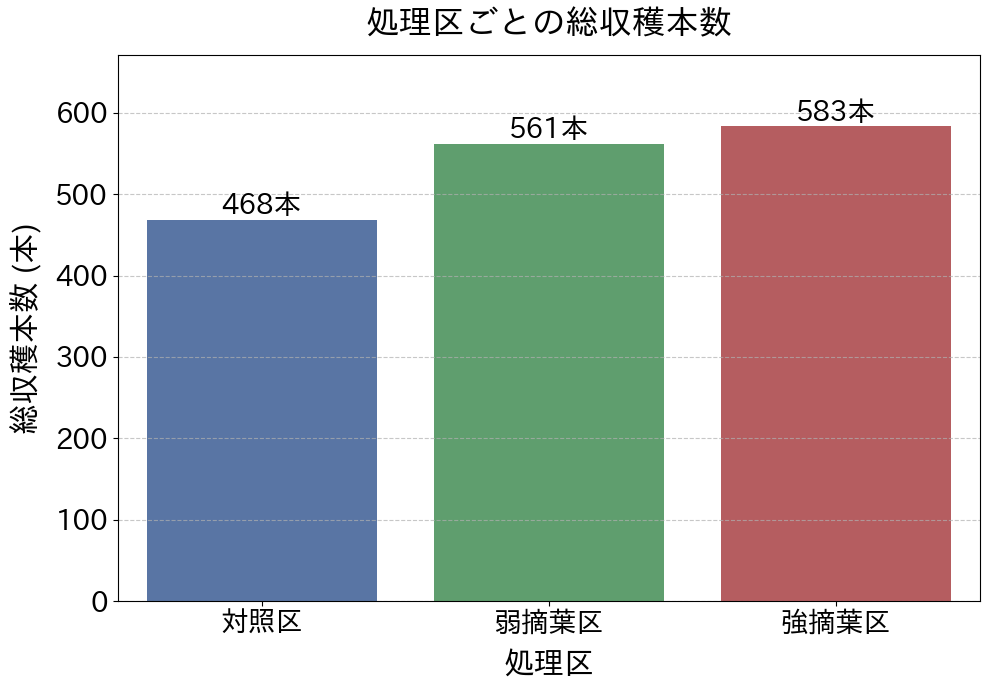

<Figure size 1200x800 with 0 Axes>

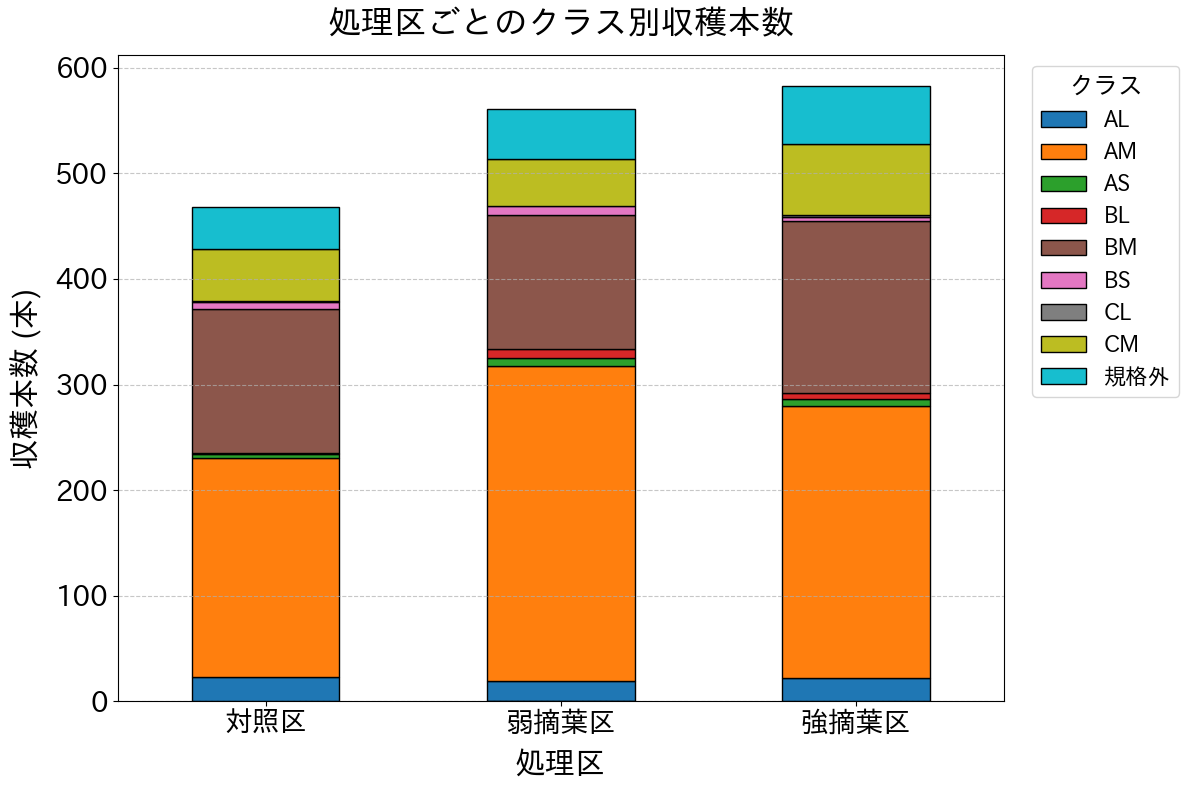

<Figure size 1200x800 with 0 Axes>

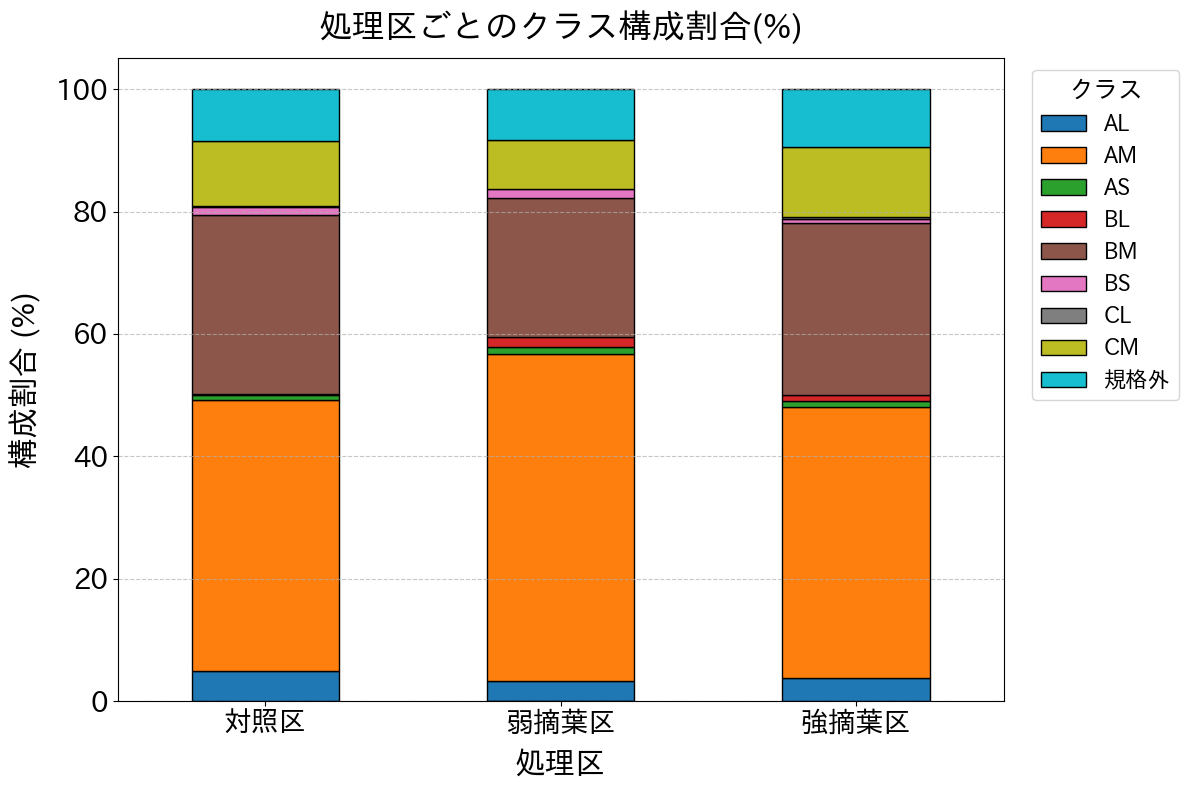

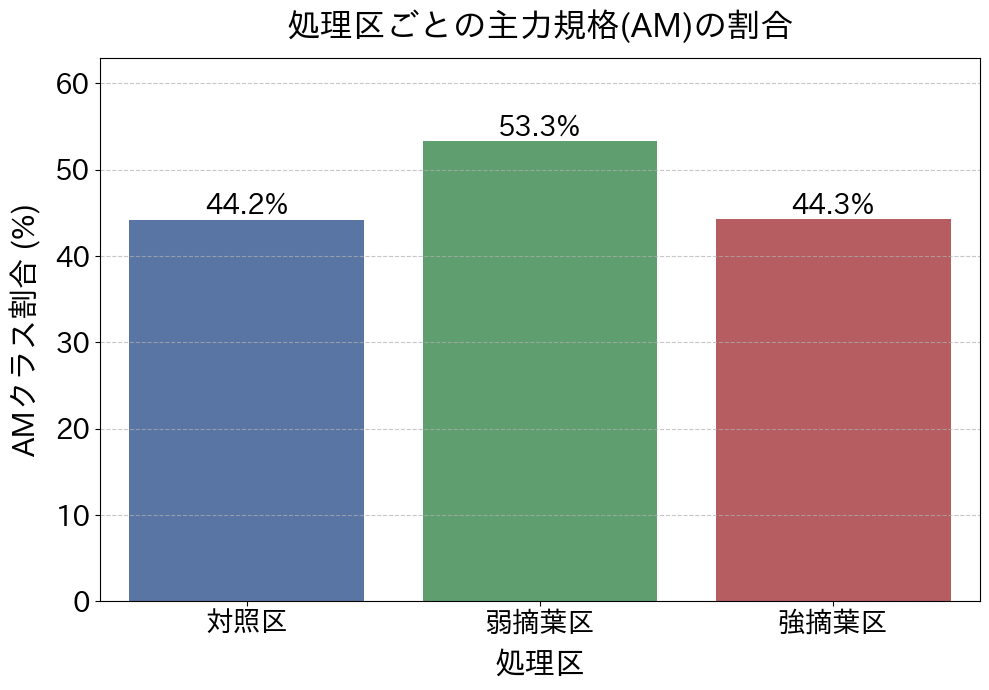


収穫本数とクラスに関するすべての個別グラフが正常に生成・保存されました。


In [3]:
!pip install japanize-matplotlib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib  # 日本語文字化け対策
import scipy.stats as stats

# 1. データの読み込み
file_path = 'sorted_survey_result.csv'
df = pd.read_csv(file_path, encoding='utf-8-sig')

# 2. 試験区を処理区にマッピング（1行 = 1本）
treatment_map = {
    2: '強摘葉区', 3: '強摘葉区', 10: '強摘葉区', 11: '強摘葉区',
    4: '弱摘葉区', 5: '弱摘葉区', 8: '弱摘葉区', 9: '弱摘葉区',
    1: '対照区', 6: '対照区', 7: '対照区', 12: '対照区'
}
df['処理区'] = df['試験区'].map(treatment_map)

treatment_order = ['対照区', '弱摘葉区', '強摘葉区']

# ランク（クラス）の順序整理（主要クラスを上位に配置）
rank_order = ['AL', 'AM', 'AS', 'BL', 'BM', 'BS', 'CL', 'CM', '規格外']
df['ランク'] = pd.Categorical(df['ランク'], categories=rank_order, ordered=True)

print("=" * 70)
print("【1. 処理区ごとの総収穫本数（データ行数）】")
print("=" * 70)
harvest_count = df['処理区'].value_counts().reindex(treatment_order)
display(pd.DataFrame({'総収穫本数(本)': harvest_count}))

print("\n" + "=" * 70)
print("【2. 処理区 × クラス（ランク）別 収穫本数・構成比】")
print("=" * 70)
crosstab_count = pd.crosstab(df['処理区'], df['ランク'], margins=True).reindex(index=treatment_order + ['All'])
print("--- 収穫本数 (本) ---")
display(crosstab_count)

crosstab_pct = pd.crosstab(df['処理区'], df['ランク'], normalize='index').reindex(treatment_order) * 100
print("\n--- 構成比 (%) ---")
display(crosstab_pct.round(2))

print("\n" + "=" * 70)
print("【3. カイ二乗検定 (独立性の検定)】")
print("=" * 70)
chi2, p_val, dof, ex = stats.chi2_contingency(pd.crosstab(df['処理区'], df['ランク']))
print(f"カイ二乗値 (Chi2): {chi2:.4f}")
print(f"自由度 (dof): {dof}")
print(f"p値 (p-value): {p_val:.4f}")
if p_val < 0.05:
    print("判定: 処理区によってクラス（ランク）構成割合に統計的な有意差があります (*)")
else:
    print("判定: 処理区によるクラス（ランク）構成割合の有意差は見られませんでした（傾向差にとどまる）")

# ==============================================================
# 4. 個別グラフの生成 (fontsize=20以上)
# ==============================================================
print("\n" + "=" * 70)
print("【4. グラフの個別表示・保存】")
print("=" * 70)

FONT_TITLE = 24
FONT_LABEL = 22
FONT_TICK = 20

custom_palette = {'対照区': '#4C72B0', '弱摘葉区': '#55A868', '強摘葉区': '#C44E52'}

# --- グラフ1: 処理区ごとの総収穫本数（棒グラフ） ---
plt.figure(figsize=(10, 7))
ax1 = sns.barplot(x=harvest_count.index, y=harvest_count.values, palette=custom_palette, hue=harvest_count.index, legend=False)
plt.title('処理区ごとの総収穫本数', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('総収穫本数 (本)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# バーの上に本数を表示
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}本',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', fontsize=FONT_TICK, color='black', xytext=(0, 10), textcoords='offset points')

plt.ylim(0, max(harvest_count.values) * 1.15)
plt.tight_layout()
plt.savefig('/content/treatment_total_harvest_count.png', dpi=300)
plt.show()

# --- グラフ2: クラス（ランク）別 収穫本数の内訳（積み上げ棒グラフ） ---
plt.figure(figsize=(12, 8))
ax2 = crosstab_count.drop('All', axis=0).drop('All', axis=1, errors='ignore').plot(
    kind='bar', stacked=True, figsize=(12, 8), colormap='tab10', edgecolor='black'
)
plt.title('処理区ごとのクラス別収穫本数', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('収穫本数 (本)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK, rotation=0)
plt.yticks(fontsize=FONT_TICK)
plt.legend(title='クラス', fontsize=16, title_fontsize=18, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_class_count_stacked.png', dpi=300)
plt.show()

# --- グラフ3: クラス（ランク）構成割合 (%)（100%積み上げ棒グラフ） ---
plt.figure(figsize=(12, 8))
ax3 = crosstab_pct.plot(
    kind='bar', stacked=True, figsize=(12, 8), colormap='tab10', edgecolor='black'
)
plt.title('処理区ごとのクラス構成割合(%)', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('構成割合 (%)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK, rotation=0)
plt.yticks(fontsize=FONT_TICK)
plt.legend(title='クラス', fontsize=16, title_fontsize=18, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/treatment_class_percentage_stacked.png', dpi=300)
plt.show()

# --- グラフ4: 秀品率・規格内割合の比較 (AM割合) ---
am_pct = crosstab_pct['AM']
plt.figure(figsize=(10, 7))
ax4 = sns.barplot(x=am_pct.index, y=am_pct.values, palette=custom_palette, hue=am_pct.index, legend=False)
plt.title('処理区ごとの主力規格(AM)の割合', fontsize=FONT_TITLE, fontweight='bold', pad=15)
plt.xlabel('処理区', fontsize=FONT_LABEL, labelpad=10)
plt.ylabel('AMクラス割合 (%)', fontsize=FONT_LABEL, labelpad=10)
plt.xticks(fontsize=FONT_TICK)
plt.yticks(fontsize=FONT_TICK)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax4.patches:
    ax4.annotate(f'{p.get_height():.1f}%',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', fontsize=FONT_TICK, color='black', xytext=(0, 10), textcoords='offset points')

plt.ylim(0, max(am_pct.values) * 1.18)
plt.tight_layout()
plt.savefig('/content/treatment_am_class_percentage.png', dpi=300)
plt.show()

print("\n収穫本数とクラスに関するすべての個別グラフが正常に生成・保存されました。")